# 03. Геометрия полос и алгоритмы трассировки

Курс «От интерференции до измерения поверхности». [Маршрут](README.md).

**Цели:** разделить обнаружение центров, продолжение линии и определение её физического номера.

Работайте сверху вниз, затем меняйте параметры и выполняйте **Restart Kernel → Run All**.
Все численные примеры учебные: они объясняют метод, а не подтверждают точность прибора.
Рекомендуемый темп: одна тетрадь за занятие, с собственными записями и упражнениями.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage, signal, interpolate, optimize

course_dir = next(p for p in [Path.cwd(), Path.cwd()/"notes"/"interferometry-course"]
                  if (p/"course_lib.py").exists())
if str(course_dir) not in sys.path:
    sys.path.insert(0, str(course_dir))
import course_lib as cl
np.set_printoptions(precision=5, suppress=True)

## 1. Полоса как линия уровня

Максимумы идеального косинуса лежат на $\varphi=2\pi k$, минимумы —
$\varphi=(2k+1)\pi$. Но экстремум яркости совпадает с линией равной фазы только
приближённо, если a,b пространственно меняются:
$$\partial_xI=\partial_xa+(\partial_xb)\cos\varphi-b\sin\varphi\,\partial_x\varphi.$$
Поэтому даже без шума градиент фона способен сместить центр полосы.

Три отдельные задачи: найти центры; соединить их в линии без перескоков;
присвоить одинаковый порядок всем фрагментам одной физической полосы.
Точность первого шага не гарантирует правильность третьего.

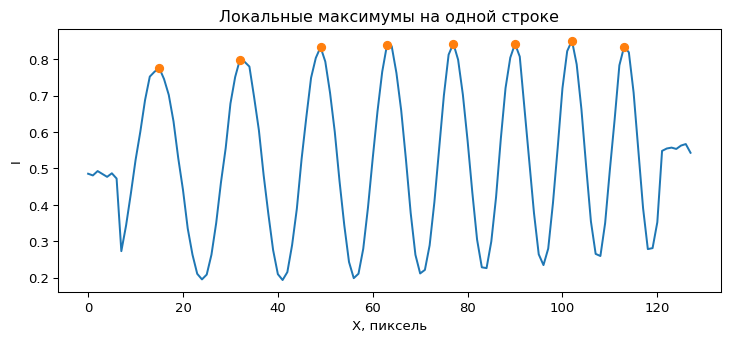

Положение найденных центров: [ 15  32  49  63  77  90 102 113]


In [2]:
s=cl.scene(n=128,carrier_x=9,carrier_y=0,bowl=.7)
image=cl.camera(s['image'],photons=12000,seed=2)
row=64
peaks,_=signal.find_peaks(image[row],distance=6,prominence=.2)
fig,ax=plt.subplots(); ax.plot(image[row]); ax.plot(peaks,image[row,peaks],'o')
ax.set(xlabel='X, пиксель',ylabel='I',title='Локальные максимумы на одной строке'); plt.show()
print('Положение найденных центров:',peaks)

## 2. Субпиксельный центр из трёх отсчётов

В окрестности максимума аппроксимируем профиль параболой
$p(t)=\alpha t^2+\beta t+\gamma$, где t=−1,0,1.
Из трёх значений $I_{-1},I_0,I_{+1}$:
$$\alpha=(I_{-1}-2I_0+I_{+1})/2,\quad\beta=(I_{+1}-I_{-1})/2.$$
Вершина $t_*=-\beta/(2\alpha)=\frac12(I_{-1}-I_{+1})/(I_{-1}-2I_0+I_{+1})$.
Это локальная аппроксимация; при плоской вершине знаменатель мал и оценка нестабильна.
Для минимума формула та же, меняется знак кривизны.

In [3]:
center_true=20.3
x=np.arange(17,25,dtype=float)
values=np.cos(2*np.pi*(x-center_true)/12)
j=int(np.argmax(values))
left,middle,right=values[j-1:j+2]
offset=.5*(left-right)/(left-2*middle+right)
print('Целочисленный / субпиксельный / истинный:',x[j],x[j]+offset,center_true)
assert abs(x[j]+offset-center_true)<.02

Целочисленный / субпиксельный / истинный: 20.0 20.295549389209764 20.3


## 3. Последовательное продолжение: предсказание и коррекция

Из текущей точки предсказываем следующую по касательной, затем ищем экстремум
поперёк полосы. Это общий принцип последовательных FTM-подобных трекеров.
Шаг должен быть меньше масштаба изменения кривизны; радиус поиска — меньше
расстояния до соседней полосы. Большой поиск повышает риск перескока.

Ниже намеренно простая версия: движение по строкам и максимум в ограниченной
окрестности предыдущего X. Она учит принципу и **не воспроизводит** все эвристики
legacy `SequentialFringeTracker` проекта. Горизонтальные полосы такой вариант
обрабатывать не умеет: нужно выбирать направление движения.

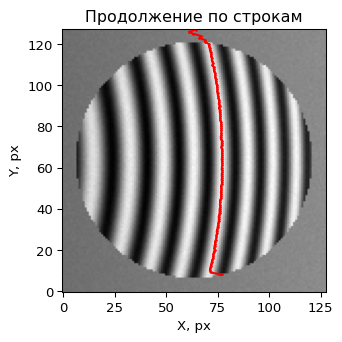

In [4]:
seed=int(peaks[len(peaks)//2])
line=cl.row_tracker(image,seed,8,radius=5)
fig,ax=plt.subplots(); ax.imshow(image,origin='lower',cmap='gray')
ax.plot(line[:,0],line[:,1],'r.-',ms=2); ax.set(title='Продолжение по строкам',xlabel='X, px',ylabel='Y, px')
plt.show()

## 4. Структурный тензор

Один градиент шумный и исчезает на вершине. Усредним **произведения** градиентов:
$$J=G_\sigma*\begin{pmatrix}I_x^2&I_xI_y\\I_xI_y&I_y^2\end{pmatrix}.$$
Для локально прямых полос больший собственный вектор направлен поперёк,
меньший — вдоль полосы. Угол нормали:
$\theta=\tfrac12\operatorname{atan2}(2J_{xy},J_{xx}-J_{yy})$.

Согласованность $q=(\lambda_{max}-\lambda_{min})/(\lambda_{max}+\lambda_{min})$
близка к 1 для выраженного одного направления. На плоском фоне q сама по себе
не доказывает наличие полезного сигнала: нужна также энергия $\mathrm{tr}\,J$.
Собственный вектор задаёт ось, а не стрелку: ±t эквивалентны. При движении
следует согласовывать знак нового касательного вектора с предыдущим.

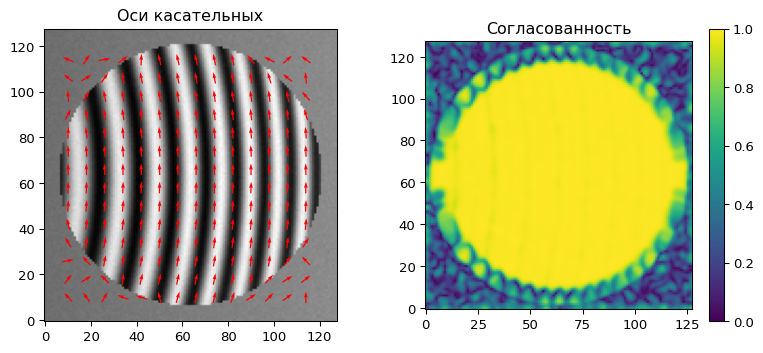

In [5]:
normal,coherence=cl.tensor_orientation(image)
gy,gx=np.gradient(image)
rows,cols=np.mgrid[10:118:8,10:118:8]
tangent=normal[rows,cols]+np.pi/2
fig,axes=plt.subplots(1,2,figsize=(10,4))
axes[0].imshow(image,origin='lower',cmap='gray')
axes[0].quiver(cols,rows,np.cos(tangent),np.sin(tangent),color='red',pivot='middle')
axes[0].set_title('Оси касательных')
im=axes[1].imshow(coherence,origin='lower',vmin=0,vmax=1); axes[1].set_title('Согласованность')
fig.colorbar(im,ax=axes[1]); plt.show()

## 5. Скелетизация: сначала область, потом линия

Бинаризация выделяет светлые области, а не точные центры. Скелетизация постепенно
удаляет граничные пиксели, стараясь сохранять связность. В Zhang–Suen рассматривают
8 соседей: число ненулевых B, число переходов 0→1 по кругу A и условия направленного
удаления в двух подитерациях. Удаление допустимо при 2≤B≤6, A=1 и выполнении
соответствующих тройных ограничений. Готовая учебная реализация есть в `course_lib.py`.

Скелет не гарантирует субпиксельного максимума. Порог может менять топологию,
а склейка обрывков — соединить разные полосы. Особенно опасны пересечения,
вырезы и узкие просветы. Морфологические параметры в пикселях зависят от масштаба.

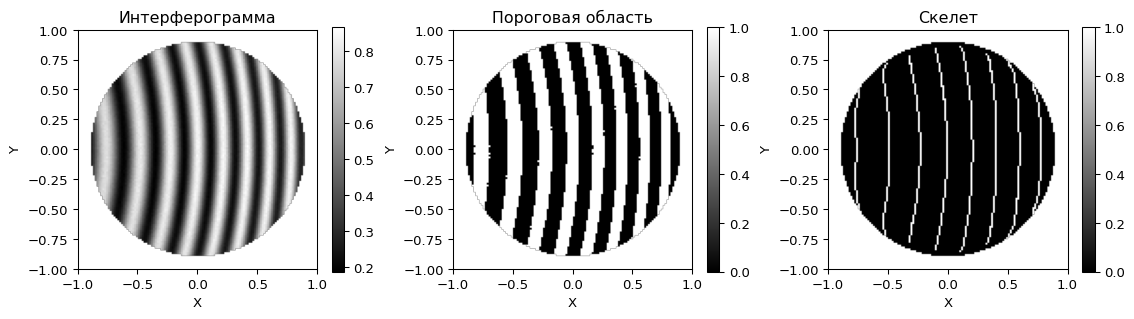

Пикселей области / скелета: 4799 753


In [6]:
local_mean=ndimage.gaussian_filter(image,5)
binary=(image>local_mean+.03)&s['mask']
skeleton=cl.thin_zhang_suen(binary)
cl.show_maps([image,binary,skeleton],['Интерферограмма','Пороговая область','Скелет'],s['mask'],cmap='gray')
print('Пикселей области / скелета:',binary.sum(),skeleton.sum())
assert skeleton.sum()<=binary.sum()

## 6. Scanline и нумерация — ещё не одно и то же

Строчный метод находит много экстремумов на каждой строке и сопоставляет их между
строками по близости, типу max/min и запрету пересечений. Это полезно при регулярных
полосах, но пропущенный экстремум может сдвинуть номера всех следующих.
На препятствии одна линия превращается в несколько фрагментов: их одинаковый
номер нужно обосновать геометрией/связями, а не дать новый номер каждому фрагменту.

## Задания

1. Сделайте радиус поиска трекера больше периода. Наблюдаете ли перескоки?
2. Сравните центры при постоянном и линейно меняющемся фоне, сохранив фазу.
3. Объясните, почему `sort(mean_x)` не нумерует произвольные полосы.
4. Найдите в `thin_zhang_suen` две разные подитерации и сопоставьте с условиями выше.

<details><summary>Разбор</summary>

Большой радиус допускает соседний экстремум. Переменный фон добавляет производную
в условие центра. Горизонтальные и концентрические линии могут иметь одинаковый
средний X; разорванная полоса может иметь разные средние X у фрагментов.
Две подитерации меняют запрещённые тройки соседей и ослабляют направленное смещение.
</details>

**В проекте:** четыре каталога `plugin-sdk/*tracker_plugin`; определение порядка
отдельно находится в `src/core/FringeOrdering.cpp`.
Далее: [номера полос и интерполяция](04_orders_and_splines.ipynb).